In [4]:
# SECTION 1 — Imports and configuration
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
import torchvision

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, precision_score, recall_score

import warnings
warnings.filterwarnings('ignore')

# REPRODUCIBILITY
def set_seed(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# KAGGLE SAFETY: Print device info
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("CUDA availability:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))


PyTorch version: 2.11.0+cu128
CUDA availability: True
GPU name: NVIDIA GeForce RTX 4050 Laptop GPU


In [5]:
# SECTION 2 — Dataset discovery and validation
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()

while PROJECT_ROOT.name != "OcuVision-AI" and PROJECT_ROOT.parent != PROJECT_ROOT:
    PROJECT_ROOT = PROJECT_ROOT.parent

base_path = PROJECT_ROOT / "data" / "preprocessed"

print("Project root:", PROJECT_ROOT)
print("Dataset path:", base_path)
print("Dataset exists:", base_path.exists())
total = 0
bad = []

if os.path.exists(base_path):
    print("dataset path:", base_path)
    for cls in sorted(os.listdir(base_path)):
        folder = os.path.join(base_path, cls)
        if not os.path.isdir(folder):
            continue
        for filename in os.listdir(folder):
            path = os.path.join(folder, filename)
            total += 1
            try:
                with Image.open(path) as img:
                    img.verify()
            except Exception as e:
                bad.append((filename, str(e)))

    print("number of images:", total)
    print("Bad/unreadable images:", len(bad))
else:
    print(f"Dataset path {base_path} not found. Please ensure it's attached.")


Project root: D:\gpt\OcuVision-AI
Dataset path: D:\gpt\OcuVision-AI\data\preprocessed
Dataset exists: True
dataset path: D:\gpt\OcuVision-AI\data\preprocessed
number of images: 10449
Bad/unreadable images: 0


In [6]:
# SECTION 3 — Class mapping
class_to_idx = {
    "N": 0,
    "D": 1,
    "G": 2,
    "C": 3,
    "A": 4,
    "H": 5,
    "M": 6
}
idx_to_class = {v: k for k, v in class_to_idx.items()}
classes = ["N", "D", "G", "C", "A", "H", "M"]

data = []
if os.path.exists(base_path):
    for label in classes:
        folder = os.path.join(base_path, label)
        if os.path.isdir(folder):
            for filename in os.listdir(folder):
                data.append({
                    "filename": filename,
                    "label": label,
                    "path": os.path.join(folder, filename)
                })

df = pd.DataFrame(data)
print("\nclass distribution:")
if len(df) > 0:
    print(df["label"].value_counts()[classes])



class distribution:
label
N    2997
D    3128
G    1646
C    1008
A     511
H     420
M     739
Name: count, dtype: int64


In [7]:
# SECTION 4 — Stratified train/validation/test split
# Previous split: Train = 8359, Validation = 1045, Test = 1045
# Total images = 10449
# 80% Train, 10% Validation, 10% Test

if len(df) > 0:
    train_df, temp_df = train_test_split(
        df,
        test_size=0.20,
        stratify=df["label"],
        random_state=42
    )

    val_df, test_df = train_test_split(
        temp_df,
        test_size=0.50,
        stratify=temp_df["label"],
        random_state=42
    )
    
    # Reset indices
    train_df = train_df.reset_index(drop=True)
    val_df = val_df.reset_index(drop=True)
    test_df = test_df.reset_index(drop=True)

    print("train/validation/test counts:")
    print("Train:", len(train_df))
    print("Validation:", len(val_df))
    print("Test:", len(test_df))
    
    # Verify no overlap
    train_paths = set(train_df['path'])
    val_paths = set(val_df['path'])
    test_paths = set(test_df['path'])
    
    print("Train/Val overlap:", len(train_paths.intersection(val_paths)))
    print("Train/Test overlap:", len(train_paths.intersection(test_paths)))
    print("Val/Test overlap:", len(val_paths.intersection(test_paths)))


train/validation/test counts:
Train: 8359
Validation: 1045
Test: 1045
Train/Val overlap: 0
Train/Test overlap: 0
Val/Test overlap: 0


In [8]:
# SECTION 5 — Image transforms
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


In [9]:
# SECTION 6 — Dataset and DataLoaders
class OcularDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row["path"]).convert("RGB")
        label = class_to_idx[row["label"]]

        if self.transform:
            image = self.transform(image)

        return image, label

if len(df) > 0:
    train_dataset = OcularDataset(train_df, train_transform)
    val_dataset = OcularDataset(val_df, eval_transform)
    test_dataset = OcularDataset(test_df, eval_transform)

    batch_size = 64

    # Kaggle num_workers issue -> use 0
    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        pin_memory=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

    print("DataLoaders created.")


DataLoaders created.


In [10]:
# SECTION 7 — ResNet-50 Model

import torch
import torch.nn as nn
from torchvision.models import resnet50, ResNet50_Weights

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

# Load pretrained ResNet-50
weights = ResNet50_Weights.DEFAULT
model = resnet50(weights=weights)

# Replace final layer for 7 classes
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, len(classes))

model = model.to(device)

print("ResNet-50 loaded successfully.")
print("Number of classes:", len(classes))

Device: cuda
ResNet-50 loaded successfully.
Number of classes: 7


In [11]:
# SECTION 8 — Loss, Optimizer and Mixed Precision

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scaler = torch.amp.GradScaler("cuda") if device.type == "cuda" else torch.amp.GradScaler("cpu")

print("Training setup ready.")

Training setup ready.


In [12]:
# SECTION 8.5 — Training and Evaluation Functions

from sklearn.metrics import f1_score
from tqdm.auto import tqdm

def train_epoch(model, loader, criterion, optimizer, scaler, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(loader, desc="Training", leave=False):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        if device.type == "cuda":
            with torch.amp.autocast("cuda"):
                outputs = model(images)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    all_labels = []
    all_predictions = []

    for images, labels in tqdm(loader, desc="Validation", leave=False):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if device.type == "cuda":
            with torch.amp.autocast("cuda"):
                outputs = model(images)
                loss = criterion(outputs, labels)
        else:
            outputs = model(images)
            loss = criterion(outputs, labels)

        running_loss += loss.item() * images.size(0)

        predictions = torch.argmax(outputs, dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

    total = len(all_labels)

    val_loss = running_loss / total
    val_acc = sum(
        p == y for p, y in zip(all_predictions, all_labels)
    ) / total

    val_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro"
    )

    return val_loss, val_acc, val_f1, all_labels, all_predictions


print("Training and evaluation functions ready.")

Training and evaluation functions ready.


In [13]:
# SECTION 9 — Training loop with checkpoint saving
if len(df) > 0:
    epochs = 10
    best_val_f1 = 0.0
    best_epoch = -1
    
    history = {
        "epoch": [],
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
        "val_f1": [],
        "lr": []
    }

    RESULTS_DIR = PROJECT_ROOT / "results" / "resnet50"
    MODELS_DIR = PROJECT_ROOT / "models"

    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    MODELS_DIR.mkdir(parents=True, exist_ok=True)

    checkpoint_path = MODELS_DIR / "resnet50_best_checkpoint.pth"
    history_path = RESULTS_DIR / "resnet50_training_history.csv"

    print("Checkpoint:", checkpoint_path)
    print("History:", history_path)
    
    # Ensure working directory exists for testing outside kaggle if needed
    os.makedirs(os.path.dirname(checkpoint_path), exist_ok=True)

    for epoch in range(1, epochs + 1):
        print(f"\nEpoch {epoch}/{epochs}")
        
        train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, scaler, device)
        val_loss, val_acc, val_f1, _, _ = evaluate(model, val_loader, criterion, device)
        
        current_lr = optimizer.param_groups[0]['lr']
        
        history["epoch"].append(epoch)
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["val_f1"].append(val_f1)
        history["lr"].append(current_lr)
        
        print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
        print(f"Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.4f} | Val Macro F1: {val_f1:.4f}")
        
        # Checkpoint saving
        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_epoch = epoch
            print(f"⭐ New best validation Macro F1: {best_val_f1:.4f}. Saving checkpoint...")
            
            checkpoint = {
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'best_val_macro_f1': best_val_f1,
                'class_names': classes
            }
            torch.save(checkpoint, checkpoint_path)
            
        # Save history
        pd.DataFrame(history).to_csv(history_path, index=False)


Checkpoint: D:\gpt\OcuVision-AI\models\resnet50_best_checkpoint.pth
History: D:\gpt\OcuVision-AI\results\resnet50\resnet50_training_history.csv

Epoch 1/10


Training:   0%|          | 0/131 [00:00<?, ?it/s]

Validation:   0%|          | 0/17 [00:00<?, ?it/s]

Train Loss: 0.9235 | Train Acc: 0.6708
Val Loss:   0.5706 | Val Acc:   0.7789 | Val Macro F1: 0.7740
⭐ New best validation Macro F1: 0.7740. Saving checkpoint...

Epoch 2/10


Training:   0%|          | 0/131 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/17 [00:00<?, ?it/s]

Train Loss: 0.1445 | Train Acc: 0.9435
Val Loss:   0.5798 | Val Acc:   0.8325 | Val Macro F1: 0.8430

Epoch 10/10


Training:   0%|          | 0/131 [00:00<?, ?it/s]

Validation:   0%|          | 0/17 [00:00<?, ?it/s]

Train Loss: 0.1254 | Train Acc: 0.9495
Val Loss:   0.5804 | Val Acc:   0.8278 | Val Macro F1: 0.8497


In [14]:
# SECTION 11 — Check local output files

print("Files in models:")
print(os.listdir(MODELS_DIR))

print("\nFiles in results/resnet50:")
print(os.listdir(RESULTS_DIR))

print(
    "\nResNet checkpoint exists:",
    checkpoint_path.exists()
)

print(
    "ResNet history exists:",
    history_path.exists()
)

Files in models:
['README.md', 'resnet50_best_checkpoint.pth']

Files in results/resnet50:
['resnet50_classification_report.png', 'resnet50_classwise_f1.png', 'resnet50_confusion_matrix.png', 'resnet50_experiment_summary.png', 'resnet50_test_metrics.png', 'resnet50_training_curves.png', 'resnet50_training_history.csv']

ResNet checkpoint exists: True
ResNet history exists: True


In [15]:
# SECTION 11 — Verify local ResNet outputs

print(
    "ResNet checkpoint exists:",
    checkpoint_path.exists()
)

print(
    "ResNet history exists:",
    history_path.exists()
)

ResNet checkpoint exists: True
ResNet history exists: True


In [16]:
# SECTION 10 — Restore best checkpoint

if len(df) > 0:
    if checkpoint_path.exists():
        print(f"Loading best checkpoint from: {checkpoint_path}")

        checkpoint = torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=False
        )

        model.load_state_dict(checkpoint["model_state_dict"])

        print(
            f"Loaded checkpoint with Validation Macro F1: "
            f"{checkpoint['best_val_macro_f1']:.4f}"
        )
    else:
        print("Checkpoint not found!")

Loading best checkpoint from: D:\gpt\OcuVision-AI\models\resnet50_best_checkpoint.pth
Loaded checkpoint with Validation Macro F1: 0.8514


In [17]:
# SECTION 11 — Test evaluation
if len(df) > 0:
    print("Evaluating on test set...")
    test_loss, test_acc, test_macro_f1, test_preds, test_labels = evaluate(model, test_loader, criterion, device)

    test_macro_prec = precision_score(test_labels, test_preds, average="macro")
    test_macro_rec = recall_score(test_labels, test_preds, average="macro")
    test_weighted_f1 = f1_score(test_labels, test_preds, average="weighted")
    
    print(f"Test Loss: {test_loss:.4f}")
    print(f"Test Accuracy: {test_acc:.4f}")
    print(f"Test Macro Precision: {test_macro_prec:.4f}")
    print(f"Test Macro Recall: {test_macro_rec:.4f}")
    print(f"Test Macro F1: {test_macro_f1:.4f}")
    print(f"Test Weighted F1: {test_weighted_f1:.4f}")


Evaluating on test set...


Validation:   0%|          | 0/17 [00:00<?, ?it/s]

Test Loss: 0.5355
Test Accuracy: 0.8067
Test Macro Precision: 0.8286
Test Macro Recall: 0.8622
Test Macro F1: 0.8402
Test Weighted F1: 0.8081


In [18]:
# SECTION 12 — Classification report
if len(df) > 0:
    print("\nClassification Report:")
    print(classification_report(test_labels, test_preds, target_names=classes, digits=4))



Classification Report:
              precision    recall  f1-score   support

           N     0.9064    0.7057    0.7936       384
           D     0.6613    0.8734    0.7527       237
           G     0.8061    0.7557    0.7801       176
           C     0.9901    1.0000    0.9950       100
           A     0.9412    1.0000    0.9697        48
           H     0.8333    0.8974    0.8642        39
           M     0.6622    0.8033    0.7259        61

    accuracy                         0.8067      1045
   macro avg     0.8286    0.8622    0.8402      1045
weighted avg     0.8265    0.8067    0.8081      1045



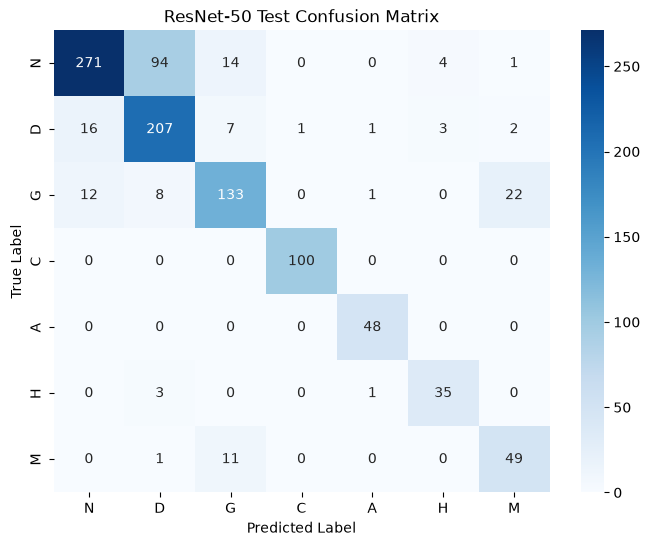

In [19]:
# SECTION 13 — Confusion matrix
if len(df) > 0:
    cm = confusion_matrix(test_labels, test_preds)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
    plt.title("ResNet-50 Test Confusion Matrix")
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()


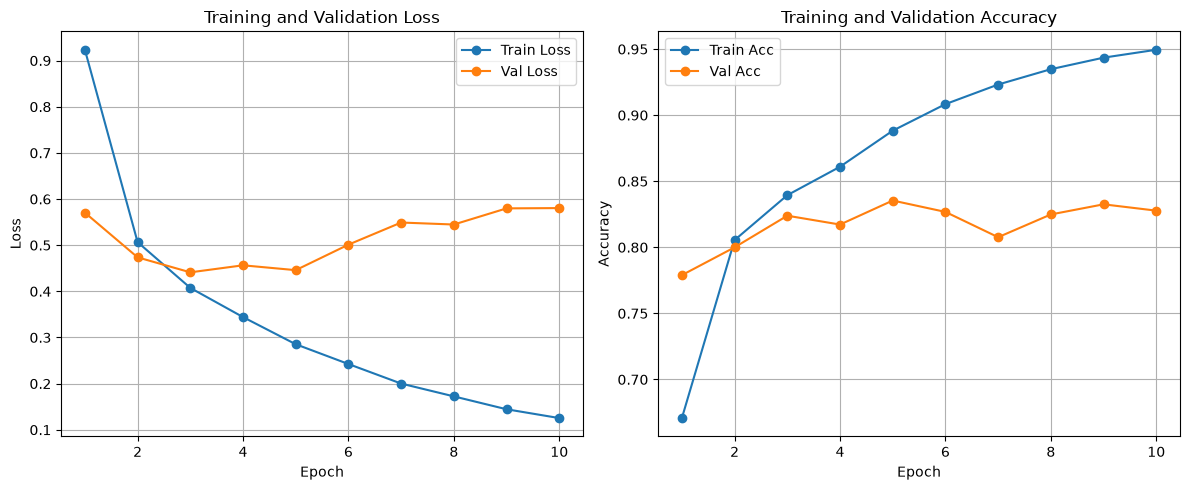

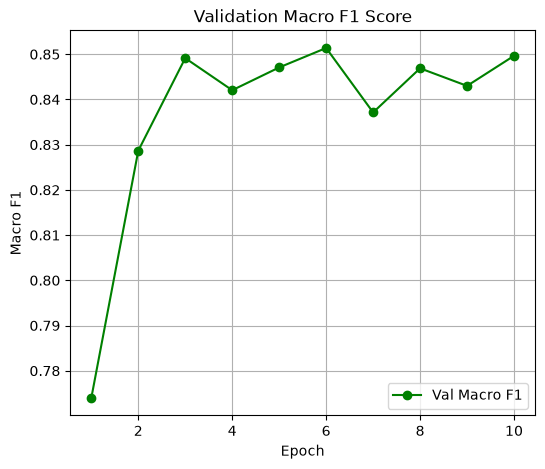

In [24]:
# SECTION 14 — Training curves
if len(df) > 0 and os.path.exists(history_path):
    hist_df = pd.read_csv(history_path)
    
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(hist_df['epoch'], hist_df['train_loss'], label='Train Loss', marker='o')
    plt.plot(hist_df['epoch'], hist_df['val_loss'], label='Val Loss', marker='o')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    
    plt.subplot(1, 2, 2)
    plt.plot(hist_df['epoch'], hist_df['train_acc'], label='Train Acc', marker='o')
    plt.plot(hist_df['epoch'], hist_df['val_acc'], label='Val Acc', marker='o')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()
    
    plt.figure(figsize=(6, 5))
    plt.plot(hist_df['epoch'], hist_df['val_f1'], label='Val Macro F1', marker='o', color='green')
    plt.title('Validation Macro F1 Score')
    plt.xlabel('Epoch')
    plt.ylabel('Macro F1')
    plt.legend()
    plt.grid(True)
    plt.show()


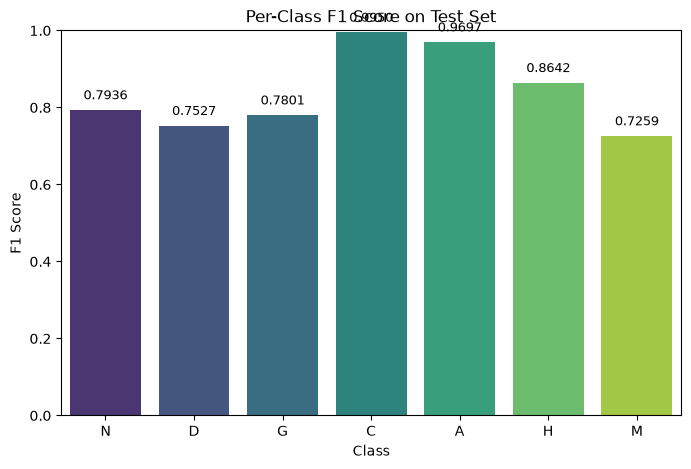

In [25]:
# SECTION 15 — Per-class F1
if len(df) > 0:
    class_f1 = f1_score(test_labels, test_preds, average=None)
    
    plt.figure(figsize=(8, 5))
    sns.barplot(x=classes, y=class_f1, palette='viridis')
    plt.title('Per-Class F1 Score on Test Set')
    plt.xlabel('Class')
    plt.ylabel('F1 Score')
    plt.ylim(0, 1)
    for i, v in enumerate(class_f1):
        plt.text(i, v + 0.02, f"{v:.4f}", ha='center', va='bottom', fontsize=9)
    plt.show()


In [26]:
# SECTION 16 — External image prediction
def predict_image(img_path, model, transform, device):
    if not os.path.exists(img_path):
        return None
    image = Image.open(img_path).convert("RGB")
    image_tensor = transform(image).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        if device.type == "cuda":
            with torch.amp.autocast("cuda"):
                outputs = model(image_tensor)
        else:
            outputs = model(image_tensor)
            probs = torch.nn.functional.softmax(outputs, dim=1)
            pred_idx = probs.argmax(dim=1).item()
            pred_prob = probs[0, pred_idx].item()
    return classes[pred_idx], pred_prob


In [27]:
# SECTION 17 — Final checkpoint verification
if len(df) > 0:
    print("\nRESNET-50 EXPERIMENT COMPLETE")
    print(f"Best validation Macro F1: {best_val_f1:.4f}")
    print(f"Best epoch: {best_epoch}")
    print(f"Test Accuracy: {test_acc:.4f}")
    print(f"Test Macro F1: {test_macro_f1:.4f}")
    print(f"Test Precision: {test_macro_prec:.4f}")
    print(f"Test Recall: {test_macro_rec:.4f}")
    if os.path.exists(checkpoint_path):
        print(f"Checkpoint path: {checkpoint_path}")
        print(f"Checkpoint file size: {os.path.getsize(checkpoint_path) / (1024*1024):.2f} MB")
    if os.path.exists(history_path):
        print(f"Training history path: {history_path}")



RESNET-50 EXPERIMENT COMPLETE
Best validation Macro F1: 0.8514
Best epoch: 6
Test Accuracy: 0.8067
Test Macro F1: 0.8402
Test Precision: 0.8286
Test Recall: 0.8622
Checkpoint path: D:\gpt\OcuVision-AI\models\resnet50_best_checkpoint.pth
Checkpoint file size: 269.64 MB
Training history path: D:\gpt\OcuVision-AI\results\resnet50\resnet50_training_history.csv


In [28]:
!pip install -q grad-cam


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [29]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os

print("Grad-CAM imported successfully")

Grad-CAM imported successfully


In [31]:
# Grad-CAM target layer for ResNet-50
target_layers = [model.layer4[-1]]

print("Model:", type(model).__name__)
print("Target layer:", model.layer4[-1])
cam = GradCAM(
    model=model,
    target_layers=target_layers
)

print("Grad-CAM initialized successfully")
sample = test_df.iloc[0]

image_path = sample["path"]

print("Image:", image_path)
print("True class:", sample["label"])

Model: ResNet
Target layer: Bottleneck(
  (conv1): Conv2d(2048, 512, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2d(512, 2048, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn3): BatchNorm2d(2048, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
)
Grad-CAM initialized successfully
Image: D:\gpt\OcuVision-AI\data\preprocessed\M\Myopia282.jpg
True class: M


Predicted class index: 2
Predicted class: G
True class: M


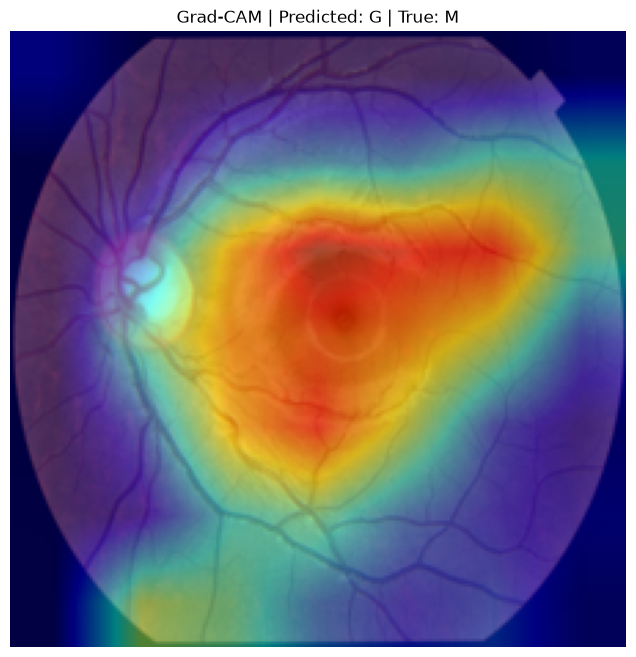

In [32]:
# Load original image
image = Image.open(image_path).convert("RGB")

# Use the SAME evaluation transform already defined in the notebook
input_tensor = eval_transform(image).unsqueeze(0).to(device)

# Prediction
model.eval()

with torch.no_grad():
    output = model(input_tensor)

predicted_class = output.argmax(dim=1).item()

print("Predicted class index:", predicted_class)
print("Predicted class:", idx_to_class[predicted_class])
print("True class:", sample["label"])

# Grad-CAM target = predicted class
targets = [
    ClassifierOutputTarget(predicted_class)
]

grayscale_cam = cam(
    input_tensor=input_tensor,
    targets=targets
)

grayscale_cam = grayscale_cam[0]

# Original image resized to model input size
rgb_image = image.resize((224, 224))

rgb_image = np.asarray(
    rgb_image
).astype(np.float32) / 255.0

# Overlay
visualization = show_cam_on_image(
    rgb_image,
    grayscale_cam,
    use_rgb=True
)

# Display
plt.figure(figsize=(8, 8))
plt.imshow(visualization)
plt.axis("off")

plt.title(
    f"Grad-CAM | "
    f"Predicted: {idx_to_class[predicted_class]} | "
    f"True: {sample['label']}"
)

plt.show()

In [34]:
# Generate Grad-CAM visualizations for several test images

gradcam_dir = RESULTS_DIR / "gradcam"
gradcam_dir.mkdir(parents=True, exist_ok=True)

num_images = 10

model.eval()

for i in range(min(num_images, len(test_df))):

    sample = test_df.iloc[i]
    image_path = sample["path"]

    image = Image.open(image_path).convert("RGB")

    input_tensor = eval_transform(image).unsqueeze(0).to(device)

    # Prediction
    with torch.no_grad():
        output = model(input_tensor)

    predicted_class = output.argmax(dim=1).item()

    # Grad-CAM
    targets = [ClassifierOutputTarget(predicted_class)]

    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=targets
    )[0]

    # Prepare original image
    rgb_image = image.resize((224, 224))
    rgb_image = np.asarray(rgb_image).astype(np.float32) / 255.0

    # Overlay
    visualization = show_cam_on_image(
        rgb_image,
        grayscale_cam,
        use_rgb=True
    )

    # Save
    output_path = gradcam_dir / f"gradcam_{i+1:02d}.png"

    Image.fromarray(visualization).save(output_path)

    print(
        f"{i+1:02d} | "
        f"True: {sample['label']} | "
        f"Predicted: {idx_to_class[predicted_class]} | "
        f"Saved: {output_path}"
    )

print("\nGrad-CAM generation complete.")
print(f"Grad-CAM directory: {gradcam_dir}")
print(os.listdir(gradcam_dir))

01 | True: M | Predicted: G | Saved: D:\gpt\OcuVision-AI\results\resnet50\gradcam\gradcam_01.png
02 | True: C | Predicted: C | Saved: D:\gpt\OcuVision-AI\results\resnet50\gradcam\gradcam_02.png
03 | True: N | Predicted: N | Saved: D:\gpt\OcuVision-AI\results\resnet50\gradcam\gradcam_03.png
04 | True: A | Predicted: A | Saved: D:\gpt\OcuVision-AI\results\resnet50\gradcam\gradcam_04.png
05 | True: C | Predicted: C | Saved: D:\gpt\OcuVision-AI\results\resnet50\gradcam\gradcam_05.png
06 | True: D | Predicted: D | Saved: D:\gpt\OcuVision-AI\results\resnet50\gradcam\gradcam_06.png
07 | True: D | Predicted: D | Saved: D:\gpt\OcuVision-AI\results\resnet50\gradcam\gradcam_07.png
08 | True: D | Predicted: D | Saved: D:\gpt\OcuVision-AI\results\resnet50\gradcam\gradcam_08.png
09 | True: N | Predicted: N | Saved: D:\gpt\OcuVision-AI\results\resnet50\gradcam\gradcam_09.png
10 | True: G | Predicted: G | Saved: D:\gpt\OcuVision-AI\results\resnet50\gradcam\gradcam_10.png

Grad-CAM generation complete.

In [35]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image

from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

# Local Grad-CAM output directory
gradcam_dir = RESULTS_DIR / "gradcam"
gradcam_dir.mkdir(parents=True, exist_ok=True)

num_images = 10

model.eval()

for i in range(min(num_images, len(test_df))):

    sample = test_df.iloc[i]
    image_path = sample["path"]

    # Load image
    image = Image.open(image_path).convert("RGB")

    # Same evaluation preprocessing
    input_tensor = eval_transform(image).unsqueeze(0).to(device)

    # -----------------------------
    # Prediction
    # -----------------------------
    with torch.no_grad():
        output = model(input_tensor)

        probabilities = torch.softmax(output, dim=1)

        predicted_class = output.argmax(dim=1).item()

        confidence = probabilities[0, predicted_class].item()

    predicted_label = idx_to_class[predicted_class]
    true_label = sample["label"]

    # -----------------------------
    # Grad-CAM
    # -----------------------------
    targets = [
        ClassifierOutputTarget(predicted_class)
    ]

    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=targets
    )[0]

    # -----------------------------
    # Prepare original image
    # -----------------------------
    rgb_image = image.resize((224, 224))

    rgb_image = np.asarray(
        rgb_image
    ).astype(np.float32) / 255.0

    # -----------------------------
    # Create overlay
    # -----------------------------
    visualization = show_cam_on_image(
        rgb_image,
        grayscale_cam,
        use_rgb=True
    )

    # -----------------------------
    # Save image
    # -----------------------------
    output_path = gradcam_dir / f"gradcam_{i+1:02d}.png"

    Image.fromarray(visualization).save(output_path)

    # -----------------------------
    # Print result
    # -----------------------------
    print(
        f"{i+1:02d} | "
        f"True: {true_label} | "
        f"Predicted: {predicted_label} | "
        f"Confidence: {confidence:.2%} | "
        f"Saved: {output_path}"
    )

print("\nGrad-CAM generation complete.")
print(f"Grad-CAM directory: {gradcam_dir}")

01 | True: M | Predicted: G | Confidence: 67.78% | Saved: D:\gpt\OcuVision-AI\results\resnet50\gradcam\gradcam_01.png
02 | True: C | Predicted: C | Confidence: 99.58% | Saved: D:\gpt\OcuVision-AI\results\resnet50\gradcam\gradcam_02.png
03 | True: N | Predicted: N | Confidence: 98.98% | Saved: D:\gpt\OcuVision-AI\results\resnet50\gradcam\gradcam_03.png
04 | True: A | Predicted: A | Confidence: 99.91% | Saved: D:\gpt\OcuVision-AI\results\resnet50\gradcam\gradcam_04.png
05 | True: C | Predicted: C | Confidence: 87.74% | Saved: D:\gpt\OcuVision-AI\results\resnet50\gradcam\gradcam_05.png
06 | True: D | Predicted: D | Confidence: 59.84% | Saved: D:\gpt\OcuVision-AI\results\resnet50\gradcam\gradcam_06.png
07 | True: D | Predicted: D | Confidence: 99.37% | Saved: D:\gpt\OcuVision-AI\results\resnet50\gradcam\gradcam_07.png
08 | True: D | Predicted: D | Confidence: 99.98% | Saved: D:\gpt\OcuVision-AI\results\resnet50\gradcam\gradcam_08.png
09 | True: N | Predicted: N | Confidence: 65.54% | Saved

     gradcam_file             image_id  \
0  gradcam_01.png        Myopia282.jpg   
1  gradcam_02.png     cataract_053.png   
2  gradcam_03.png         488_left.jpg   
3  gradcam_04.png  0_RFiMD_90_ARMD.png   
4  gradcam_05.png      _57_8463167.jpg   
5  gradcam_06.png        291_right.jpg   
6  gradcam_07.png        4341_left.jpg   
7  gradcam_08.png           DR1014.jpg   
8  gradcam_09.png       2432_right.jpg   
9  gradcam_10.png       Glaucoma29.jpg   

                                          image_path true_class  \
0  D:\gpt\OcuVision-AI\data\preprocessed\M\Myopia...          M   
1  D:\gpt\OcuVision-AI\data\preprocessed\C\catara...          C   
2  D:\gpt\OcuVision-AI\data\preprocessed\N\488_le...          N   
3  D:\gpt\OcuVision-AI\data\preprocessed\A\0_RFiM...          A   
4  D:\gpt\OcuVision-AI\data\preprocessed\C\_57_84...          C   
5  D:\gpt\OcuVision-AI\data\preprocessed\D\291_ri...          D   
6  D:\gpt\OcuVision-AI\data\preprocessed\D\4341_l...          D   
7

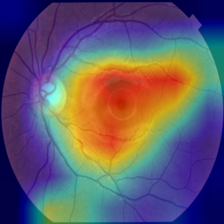

gradcam_02.png


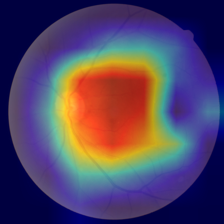

gradcam_03.png


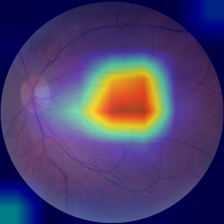

gradcam_04.png


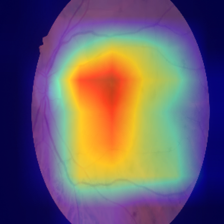

gradcam_05.png


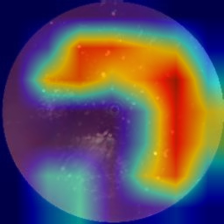

gradcam_06.png


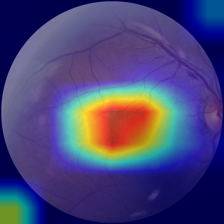

gradcam_07.png


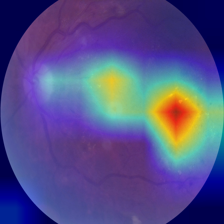

gradcam_08.png


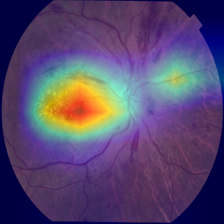

gradcam_09.png


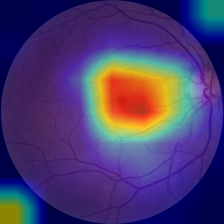

gradcam_10.png


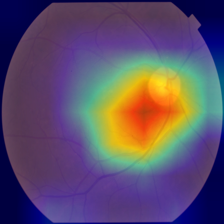


=== CHECKING SAVED MODEL AND RESULTS ===

 D:\gpt\OcuVision-AI\models\resnet50_best_checkpoint.pth
Exists: True
Size: 269.64 MB

 D:\gpt\OcuVision-AI\results\resnet50
Exists: True
Contents:
   gradcam
   resnet50_classification_report.png
   resnet50_classwise_f1.png
   resnet50_confusion_matrix.png
   resnet50_experiment_summary.png
   resnet50_test_metrics.png
   resnet50_training_curves.png
   resnet50_training_history.csv

 D:\gpt\OcuVision-AI\results\resnet50\gradcam
Exists: True
Contents:
   gradcam_01.png
   gradcam_02.png
   gradcam_03.png
   gradcam_04.png
   gradcam_05.png
   gradcam_06.png
   gradcam_07.png
   gradcam_08.png
   gradcam_09.png
   gradcam_10.png
   gradcam_summary.csv


In [36]:
# ============================================
# Grad-CAM summary + visualization + verification
# ============================================

import os
import pandas as pd
import torch
from PIL import Image
from IPython.display import display

# Local Grad-CAM directory
gradcam_dir = RESULTS_DIR / "gradcam"
gradcam_dir.mkdir(parents=True, exist_ok=True)


# ============================================
# 1. Create Grad-CAM summary CSV
# ============================================

records = []

model.eval()

for i in range(min(10, len(test_df))):

    sample = test_df.iloc[i]

    image_path = sample["path"]

    image = Image.open(image_path).convert("RGB")

    input_tensor = eval_transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(input_tensor)
        probabilities = torch.softmax(output, dim=1)

        predicted_class = output.argmax(dim=1).item()
        confidence = probabilities[0, predicted_class].item()

    records.append({
        "gradcam_file": f"gradcam_{i+1:02d}.png",
        "image_id": sample.get("filename", ""),
        "image_path": image_path,
        "true_class": sample["label"],
        "predicted_class": idx_to_class[predicted_class],
        "confidence": confidence,
        "correct": sample["label"] == idx_to_class[predicted_class]
    })


gradcam_df = pd.DataFrame(records)

csv_path = gradcam_dir / "gradcam_summary.csv"

gradcam_df.to_csv(csv_path, index=False)

print(gradcam_df)
print()
print("Saved:", csv_path)


# ============================================
# 2. Display saved Grad-CAM images
# ============================================

print("\n=== SAVED GRAD-CAM IMAGES ===")

for filename in sorted(gradcam_dir.iterdir()):

    if filename.suffix.lower() == ".png":

        print(filename.name)

        display(Image.open(filename))


# ============================================
# 3. Verify saved model and results
# ============================================

print("\n=== CHECKING SAVED MODEL AND RESULTS ===")

paths = [
    checkpoint_path,
    RESULTS_DIR,
    gradcam_dir,
]

for path in paths:

    print("\n", path)
    print("Exists:", path.exists())

    if path.is_file():

        print(
            "Size:",
            round(path.stat().st_size / (1024 * 1024), 2),
            "MB"
        )

    elif path.is_dir():

        print("Contents:")

        for item in sorted(path.iterdir()):

            print("  ", item.name)

In [37]:
import torch

print("=== RESNET50 CHECKPOINT VERIFICATION ===")

# Use the local checkpoint path defined earlier
print("Checkpoint path:", checkpoint_path)

if checkpoint_path.exists():

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    print("Checkpoint found.")
    print("Epoch saved:", checkpoint.get("epoch"))
    print(
        "Best validation Macro F1:",
        checkpoint.get("best_val_macro_f1")
    )
    print("Classes:", checkpoint.get("class_names"))

    print(
        "Checkpoint size:",
        f"{checkpoint_path.stat().st_size / (1024 * 1024):.2f} MB"
    )

else:
    print("Checkpoint NOT FOUND.")

=== RESNET50 CHECKPOINT VERIFICATION ===
Checkpoint path: D:\gpt\OcuVision-AI\models\resnet50_best_checkpoint.pth
Checkpoint found.
Epoch saved: 6
Best validation Macro F1: 0.8513801364279022
Classes: ['N', 'D', 'G', 'C', 'A', 'H', 'M']
Checkpoint size: 269.64 MB


In [38]:
# ============================================
# PHASE 3 — XAI QUALITY CHECK
# ============================================

import pandas as pd
from pathlib import Path

xai_dir = RESULTS_DIR / "gradcam"
summary_path = xai_dir / "gradcam_summary.csv"

if not summary_path.exists():
    print("Grad-CAM summary not found:", summary_path)
else:
    gradcam_df = pd.read_csv(summary_path)

    print("Grad-CAM samples:", len(gradcam_df))
    display(gradcam_df)

Grad-CAM samples: 10


,gradcam_file,image_id,image_path,true_class,predicted_class,confidence,correct
0,gradcam_01.png,Myopia282.jpg,D:\gpt\OcuVision-AI\data\preprocessed\M\Myopia...,M,G,0.677765,False
1,gradcam_02.png,cataract_053.png,D:\gpt\OcuVision-AI\data\preprocessed\C\catara...,C,C,0.995763,True
2,gradcam_03.png,488_left.jpg,D:\gpt\OcuVision-AI\data\preprocessed\N\488_le...,N,N,0.989770,True
3,gradcam_04.png,0_RFiMD_90_ARMD.png,D:\gpt\OcuVision-AI\data\preprocessed\A\0_RFiM...,A,A,0.999071,True
4,gradcam_05.png,_57_8463167.jpg,D:\gpt\OcuVision-AI\data\preprocessed\C\_57_84...,C,C,0.877420,True
5,gradcam_06.png,291_right.jpg,D:\gpt\OcuVision-AI\data\preprocessed\D\291_ri...,D,D,0.598434,True
6,gradcam_07.png,4341_left.jpg,D:\gpt\OcuVision-AI\data\preprocessed\D\4341_l...,D,D,0.993749,True
7,gradcam_08.png,DR1014.jpg,D:\gpt\OcuVision-AI\data\preprocessed\D\DR1014...,D,D,0.999763,True
8,gradcam_09.png,2432_right.jpg,D:\gpt\OcuVision-AI\data\preprocessed\N\2432_r...,N,N,0.655419,True
9,gradcam_10.png,Glaucoma29.jpg,D:\gpt\OcuVision-AI\data\preprocessed\G\Glauco...,G,G,0.996543,True


In [39]:
# ============================================
# XAI QUALITY ASSESSMENT TEMPLATE
# ============================================

xai_quality_df = gradcam_df[
    [
        "gradcam_file",
        "image_id",
        "true_class",
        "predicted_class",
        "confidence",
        "correct"
    ]
].copy()

# Manual assessment columns
xai_quality_df["focus_quality"] = ""
xai_quality_df["relevant_region"] = ""
xai_quality_df["background_focus"] = ""
xai_quality_df["visual_comment"] = ""

quality_path = xai_dir / "xai_quality_assessment.csv"

xai_quality_df.to_csv(quality_path, index=False)

print("XAI quality assessment template created:")
print(quality_path)

display(xai_quality_df)

XAI quality assessment template created:
D:\gpt\OcuVision-AI\results\resnet50\gradcam\xai_quality_assessment.csv


,gradcam_file,image_id,true_class,predicted_class,confidence,correct,focus_quality,relevant_region,background_focus,visual_comment
0,gradcam_01.png,Myopia282.jpg,M,G,0.677765,False,,,,
1,gradcam_02.png,cataract_053.png,C,C,0.995763,True,,,,
2,gradcam_03.png,488_left.jpg,N,N,0.989770,True,,,,
3,gradcam_04.png,0_RFiMD_90_ARMD.png,A,A,0.999071,True,,,,
4,gradcam_05.png,_57_8463167.jpg,C,C,0.877420,True,,,,
5,gradcam_06.png,291_right.jpg,D,D,0.598434,True,,,,
6,gradcam_07.png,4341_left.jpg,D,D,0.993749,True,,,,
7,gradcam_08.png,DR1014.jpg,D,D,0.999763,True,,,,
8,gradcam_09.png,2432_right.jpg,N,N,0.655419,True,,,,
9,gradcam_10.png,Glaucoma29.jpg,G,G,0.996543,True,,,,



--- gradcam_01.png ---


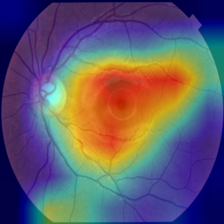


--- gradcam_02.png ---


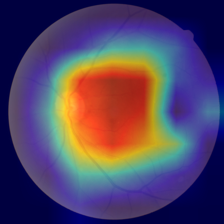


--- gradcam_03.png ---


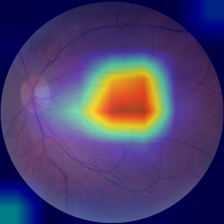


--- gradcam_04.png ---


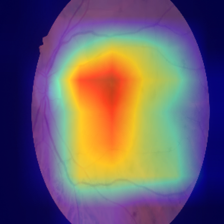


--- gradcam_05.png ---


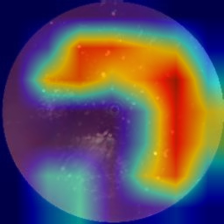


--- gradcam_06.png ---


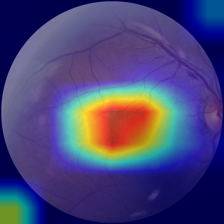


--- gradcam_07.png ---


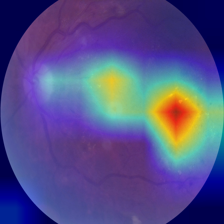


--- gradcam_08.png ---


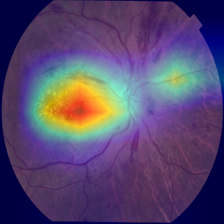


--- gradcam_09.png ---


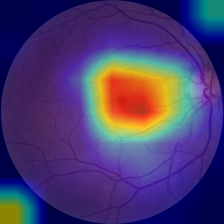


--- gradcam_10.png ---


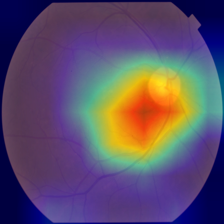

In [40]:
# ============================================
# PHASE 3B — DISPLAY ALL GRAD-CAM RESULTS
# ============================================

from PIL import Image
from IPython.display import display

gradcam_dir = RESULTS_DIR / "gradcam"

for filename in sorted(gradcam_dir.glob("gradcam_*.png")):
    print(f"\n--- {filename.name} ---")
    display(Image.open(filename))

In [42]:
# ============================================
# PHASE 3 — FINAL XAI QUALITY ASSESSMENT
# ============================================

import pandas as pd

xai_dir = RESULTS_DIR / "gradcam"
quality_path = xai_dir / "xai_quality_assessment.csv"

xai_assessment = pd.DataFrame([
    {
        "gradcam_file": "gradcam_01.png",
        "focus_quality": "Moderate",
        "relevant_region": "Yes",
        "background_focus": "Moderate",
        "visual_comment": "Main activation is within the fundus, but there is additional activation near image boundaries."
    },
    {
        "gradcam_file": "gradcam_02.png",
        "focus_quality": "Good",
        "relevant_region": "Yes",
        "background_focus": "Low",
        "visual_comment": "Strong, concentrated activation within the ocular region."
    },
    {
        "gradcam_file": "gradcam_03.png",
        "focus_quality": "Good",
        "relevant_region": "Yes",
        "background_focus": "Moderate",
        "visual_comment": "Main activation is appropriately inside the fundus, with some corner activation."
    },
    {
        "gradcam_file": "gradcam_04.png",
        "focus_quality": "Good",
        "relevant_region": "Yes",
        "background_focus": "Low",
        "visual_comment": "Activation is strongly concentrated within the retinal image region."
    },
    {
        "gradcam_file": "gradcam_05.png",
        "focus_quality": "Moderate",
        "relevant_region": "Yes",
        "background_focus": "Moderate",
        "visual_comment": "Broad activation across the fundus; less localized than some other samples."
    },
    {
        "gradcam_file": "gradcam_06.png",
        "focus_quality": "Moderate",
        "relevant_region": "Yes",
        "background_focus": "Moderate",
        "visual_comment": "Main activation is inside the fundus, but there is noticeable activation near the lower image boundary."
    },
    {
        "gradcam_file": "gradcam_07.png",
        "focus_quality": "Good",
        "relevant_region": "Yes",
        "background_focus": "Low",
        "visual_comment": "Strong activation remains within the ocular image and is associated with a correct high-confidence prediction."
    },
    {
        "gradcam_file": "gradcam_08.png",
        "focus_quality": "Good",
        "relevant_region": "Yes",
        "background_focus": "Low",
        "visual_comment": "Strong localized activation within the retinal region and very high-confidence correct prediction."
    },
    {
        "gradcam_file": "gradcam_09.png",
        "focus_quality": "Moderate",
        "relevant_region": "Yes",
        "background_focus": "Moderate",
        "visual_comment": "Main activation is within the fundus, but corner artifacts are visible."
    },
    {
        "gradcam_file": "gradcam_10.png",
        "focus_quality": "Good",
        "relevant_region": "Yes",
        "background_focus": "Low",
        "visual_comment": "Strong activation concentrated within the ocular region with little obvious external activation."
    }
])

# Preserve prediction metadata from the existing summary
metadata = gradcam_df[
    [
        "gradcam_file",
        "image_id",
        "true_class",
        "predicted_class",
        "confidence",
        "correct"
    ]
].copy()

final_xai_df = metadata.merge(
    xai_assessment,
    on="gradcam_file",
    how="left"
)

final_xai_df.to_csv(quality_path, index=False)

print("=== FINAL XAI QUALITY ASSESSMENT ===")
display(final_xai_df)

print("\nSaved to:")
print(quality_path)
# ============================================
# PHASE 3 — XAI SUMMARY
# ============================================

print("=== XAI QUALITY SUMMARY ===")

print("Total Grad-CAM samples:", len(final_xai_df))

print(
    "Good focus:",
    (final_xai_df["focus_quality"] == "Good").sum()
)

print(
    "Moderate focus:",
    (final_xai_df["focus_quality"] == "Moderate").sum()
)

print(
    "Poor focus:",
    (final_xai_df["focus_quality"] == "Poor").sum()
)

print(
    "Relevant-region focus:",
    (final_xai_df["relevant_region"] == "Yes").sum(),
    "/",
    len(final_xai_df)
)

print(
    "Low background focus:",
    (final_xai_df["background_focus"] == "Low").sum(),
    "/",
    len(final_xai_df)
)

print("\nAssessment file:")
print(quality_path)

=== FINAL XAI QUALITY ASSESSMENT ===


,gradcam_file,image_id,true_class,predicted_class,confidence,correct,focus_quality,relevant_region,background_focus,visual_comment
0,gradcam_01.png,Myopia282.jpg,M,G,0.677765,False,Moderate,Yes,Moderate,"Main activation is within the fundus, but ther..."
1,gradcam_02.png,cataract_053.png,C,C,0.995763,True,Good,Yes,Low,"Strong, concentrated activation within the ocu..."
2,gradcam_03.png,488_left.jpg,N,N,0.989770,True,Good,Yes,Moderate,Main activation is appropriately inside the fu...
3,gradcam_04.png,0_RFiMD_90_ARMD.png,A,A,0.999071,True,Good,Yes,Low,Activation is strongly concentrated within the...
4,gradcam_05.png,_57_8463167.jpg,C,C,0.877420,True,Moderate,Yes,Moderate,Broad activation across the fundus; less local...
5,gradcam_06.png,291_right.jpg,D,D,0.598434,True,Moderate,Yes,Moderate,"Main activation is inside the fundus, but ther..."
6,gradcam_07.png,4341_left.jpg,D,D,0.993749,True,Good,Yes,Low,Strong activation remains within the ocular im...
7,gradcam_08.png,DR1014.jpg,D,D,0.999763,True,Good,Yes,Low,Strong localized activation within the retinal...
8,gradcam_09.png,2432_right.jpg,N,N,0.655419,True,Moderate,Yes,Moderate,"Main activation is within the fundus, but corn..."
9,gradcam_10.png,Glaucoma29.jpg,G,G,0.996543,True,Good,Yes,Low,Strong activation concentrated within the ocul...



Saved to:
D:\gpt\OcuVision-AI\results\resnet50\gradcam\xai_quality_assessment.csv
=== XAI QUALITY SUMMARY ===
Total Grad-CAM samples: 10
Good focus: 6
Moderate focus: 4
Poor focus: 0
Relevant-region focus: 10 / 10
Low background focus: 5 / 10

Assessment file:
D:\gpt\OcuVision-AI\results\resnet50\gradcam\xai_quality_assessment.csv


In [ ]:
# ============================================================
# PHASE 3 FINALIZATION + PHASE 4 EXTERNAL INFERENCE + XAI
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import torch
from PIL import Image
from IPython.display import display
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image


# ------------------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd().resolve()

while PROJECT_ROOT.name != "OcuVision-AI" and PROJECT_ROOT.parent != PROJECT_ROOT:
    PROJECT_ROOT = PROJECT_ROOT.parent

RESULTS_DIR = PROJECT_ROOT / "results" / "resnet50"
MODELS_DIR = PROJECT_ROOT / "models"

# Existing ResNet Grad-CAM directory
GRADCAM_DIR = RESULTS_DIR / "gradcam"

# New external inference directories
EXTERNAL_DIR = PROJECT_ROOT / "data" / "external_images"
EXTERNAL_RESULTS_DIR = RESULTS_DIR / "external_inference"
EXTERNAL_GRADCAM_DIR = EXTERNAL_RESULTS_DIR / "gradcam"

EXTERNAL_DIR.mkdir(parents=True, exist_ok=True)
EXTERNAL_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
EXTERNAL_GRADCAM_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. FINALIZE PHASE 3 XAI ASSESSMENT
# ------------------------------------------------------------

quality_path = GRADCAM_DIR / "xai_quality_assessment.csv"
summary_path = GRADCAM_DIR / "gradcam_summary.csv"

if summary_path.exists():

    gradcam_df = pd.read_csv(summary_path)

    xai_assessment = pd.DataFrame([
        ["gradcam_01.png", "Moderate", "Yes", "Moderate",
         "Main activation is within the fundus, but there is additional activation near image boundaries."],

        ["gradcam_02.png", "Good", "Yes", "Low",
         "Strong, concentrated activation within the ocular region."],

        ["gradcam_03.png", "Good", "Yes", "Moderate",
         "Main activation is appropriately inside the fundus, with some corner activation."],

        ["gradcam_04.png", "Good", "Yes", "Low",
         "Activation is strongly concentrated within the retinal image region."],

        ["gradcam_05.png", "Moderate", "Yes", "Moderate",
         "Broad activation across the fundus; less localized than some other samples."],

        ["gradcam_06.png", "Moderate", "Yes", "Moderate",
         "Main activation is inside the fundus, but there is noticeable activation near the lower image boundary."],

        ["gradcam_07.png", "Good", "Yes", "Low",
         "Strong activation remains within the ocular image and is associated with a correct high-confidence prediction."],

        ["gradcam_08.png", "Good", "Yes", "Low",
         "Strong localized activation within the retinal region and very high-confidence correct prediction."],

        ["gradcam_09.png", "Moderate", "Yes", "Moderate",
         "Main activation is within the fundus, but corner artifacts are visible."],

        ["gradcam_10.png", "Good", "Yes", "Low",
         "Strong activation concentrated within the ocular region with little obvious external activation."]
    ], columns=[
        "gradcam_file",
        "focus_quality",
        "relevant_region",
        "background_focus",
        "visual_comment"
    ])

    metadata_columns = [
        "gradcam_file",
        "image_id",
        "true_class",
        "predicted_class",
        "confidence",
        "correct"
    ]

    metadata = gradcam_df[metadata_columns].copy()

    final_xai_df = metadata.merge(
        xai_assessment,
        on="gradcam_file",
        how="left"
    )

    final_xai_df.to_csv(quality_path, index=False)

    print("=" * 60)
    print("PHASE 3 — XAI QUALITY CHECK COMPLETE")
    print("=" * 60)

    print(f"Total Grad-CAM samples: {len(final_xai_df)}")
    print(
        f"Good focus: "
        f"{(final_xai_df['focus_quality'] == 'Good').sum()}/"
        f"{len(final_xai_df)}"
    )
    print(
        f"Moderate focus: "
        f"{(final_xai_df['focus_quality'] == 'Moderate').sum()}/"
        f"{len(final_xai_df)}"
    )
    print(
        f"Poor focus: "
        f"{(final_xai_df['focus_quality'] == 'Poor').sum()}/"
        f"{len(final_xai_df)}"
    )
    print(
        f"Relevant-region focus: "
        f"{(final_xai_df['relevant_region'] == 'Yes').sum()}/"
        f"{len(final_xai_df)}"
    )
    print(
        f"Low background focus: "
        f"{(final_xai_df['background_focus'] == 'Low').sum()}/"
        f"{len(final_xai_df)}"
    )

    print("\nSaved:")
    print(quality_path)

else:
    print("WARNING: gradcam_summary.csv was not found.")
    print("Phase 3 metadata could not be finalized.")


# ------------------------------------------------------------
# 3. PHASE 4 — EXTERNAL IMAGE INFERENCE SETUP
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("PHASE 4 — EXTERNAL / NEW IMAGE INFERENCE")
print("=" * 60)

print("\nExternal image folder:")
print(EXTERNAL_DIR)

print("\nExternal results folder:")
print(EXTERNAL_RESULTS_DIR)


# ------------------------------------------------------------
# 4. CHECK THAT THE TRAINED MODEL IS AVAILABLE
# ------------------------------------------------------------

if "model" not in globals():
    raise RuntimeError(
        "ResNet50 model is not currently loaded. "
        "Run the model/checkpoint cells before using Phase 4."
    )

if "eval_transform" not in globals():
    raise RuntimeError(
        "eval_transform is not available. "
        "Run the ResNet50 transform cells first."
    )

if "idx_to_class" not in globals():
    raise RuntimeError(
        "idx_to_class is not available. "
        "Run the ResNet50 class-mapping cell first."
    )

if "cam" not in globals():
    raise RuntimeError(
        "Grad-CAM object 'cam' is not available. "
        "Run the ResNet50 Grad-CAM setup cell first."
    )


# ------------------------------------------------------------
# 5. EXTERNAL INFERENCE FUNCTION
# ------------------------------------------------------------

def predict_external_image(image_path):
    """
    Run ResNet50 prediction + Grad-CAM on a new image.

    Important:
    These images are NOT assumed to have ground-truth labels.
    Therefore this function reports prediction + confidence,
    but does NOT claim correctness or validation accuracy.
    """

    image_path = Path(image_path)

    image = Image.open(image_path).convert("RGB")

    input_tensor = eval_transform(image).unsqueeze(0).to(device)

    model.eval()

    with torch.no_grad():

        if device.type == "cuda":
            with torch.amp.autocast("cuda"):
                output = model(input_tensor)
        else:
            output = model(input_tensor)

        probabilities = torch.softmax(output, dim=1)

        predicted_class = output.argmax(dim=1).item()

        confidence = probabilities[
            0,
            predicted_class
        ].item()

    predicted_label = idx_to_class[predicted_class]

    # --------------------------------------------------------
    # Generate Grad-CAM for predicted class
    # --------------------------------------------------------

    targets = [
        ClassifierOutputTarget(predicted_class)
    ]

    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=targets
    )[0]

    # Convert image to 224x224 RGB for Grad-CAM visualization
    rgb_image = image.resize((224, 224))

    rgb_image = (
        np.asarray(rgb_image)
        .astype(np.float32)
        / 255.0
    )

    visualization = show_cam_on_image(
        rgb_image,
        grayscale_cam,
        use_rgb=True
    )

    # Save Grad-CAM
    gradcam_filename = (
        image_path.stem + "_gradcam.png"
    )

    gradcam_path = (
        EXTERNAL_GRADCAM_DIR /
        gradcam_filename
    )

    Image.fromarray(
        visualization
    ).save(gradcam_path)

    return {
        "image": image_path.name,
        "predicted_class": predicted_label,
        "confidence": confidence,
        "gradcam_file": gradcam_filename,
        "gradcam_path": str(gradcam_path),
        "ground_truth": "Unknown",
        "validated": False
    }


# ------------------------------------------------------------
# 6. FIND EXTERNAL IMAGES
# ------------------------------------------------------------

image_extensions = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff",
    ".webp"
}

external_images = sorted([
    p for p in EXTERNAL_DIR.iterdir()
    if p.is_file()
    and p.suffix.lower() in image_extensions
])



PHASE 3 — XAI QUALITY CHECK COMPLETE
Total Grad-CAM samples: 10
Good focus: 6/10
Moderate focus: 4/10
Poor focus: 0/10
Relevant-region focus: 10/10
Low background focus: 5/10

Saved:
D:\gpt\OcuVision-AI\results\resnet50\gradcam\xai_quality_assessment.csv

PHASE 4 — EXTERNAL / NEW IMAGE INFERENCE

External image folder:
D:\gpt\OcuVision-AI\data\external_images

External results folder:
D:\gpt\OcuVision-AI\results\resnet50\external_inference


: 

In [46]:

# ------------------------------------------------------------
# 6. FIND EXTERNAL IMAGES
# ------------------------------------------------------------

image_extensions = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff",
    ".webp"
}

external_images = sorted([
    p for p in EXTERNAL_DIR.iterdir()
    if p.is_file()
    and p.suffix.lower() in image_extensions
])


# ------------------------------------------------------------
# 7. RUN EXTERNAL INFERENCE IF IMAGES ARE AVAILABLE
# ------------------------------------------------------------

if len(external_images) == 0:

    print("\nNo external images found yet.")

    print("\nPut new retinal/ocular images here:")
    print(EXTERNAL_DIR)

    print("\nSupported formats:")
    print(", ".join(sorted(image_extensions)))

    print("\nOnce images are placed there, rerun this SAME cell.")

else:

    print(f"\nFound {len(external_images)} external image(s).")
    print("Running ResNet50 inference + Grad-CAM...\n")

    external_records = []

    for image_path in external_images:

        try:

            result = predict_external_image(
                image_path
            )

            external_records.append(result)

            print(
                f"{result['image']}  →  "
                f"{result['predicted_class']}  "
                f"({result['confidence'] * 100:.2f}%)"
            )

        except Exception as e:

            print(
                f"ERROR processing {image_path.name}: "
                f"{e}"
            )


    # --------------------------------------------------------
    # 8. SAVE EXTERNAL PREDICTIONS
    # --------------------------------------------------------

    if external_records:

        external_df = pd.DataFrame(
            external_records
        )

        external_csv = (
            EXTERNAL_RESULTS_DIR /
            "external_inference_results.csv"
        )

        external_df.to_csv(
            external_csv,
            index=False
        )

        print("\n" + "-" * 60)
        print("EXTERNAL INFERENCE RESULTS")
        print("-" * 60)

        display(
            external_df[
                [
                    "image",
                    "predicted_class",
                    "confidence",
                    "ground_truth",
                    "validated",
                    "gradcam_file"
                ]
            ]
        )

        print("\nSaved results:")
        print(external_csv)

        print("\nSaved Grad-CAM images:")
        print(EXTERNAL_GRADCAM_DIR)

        # ----------------------------------------------------
        # 9. DISPLAY GENERATED GRAD-CAM IMAGES
        # ----------------------------------------------------

        print("\n" + "-" * 60)
        print("EXTERNAL IMAGE GRAD-CAM RESULTS")
        print("-" * 60)

        for record in external_records:

            gradcam_path = Path(
                record["gradcam_path"]
            )

            if gradcam_path.exists():

                print(
                    f"\n{record['image']} → "
                    f"{record['predicted_class']} "
                    f"({record['confidence'] * 100:.2f}%)"
                )

                display(
                    Image.open(gradcam_path)
                )


# ------------------------------------------------------------
# 10. FINAL STATUS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("CURRENT PROJECT STATUS")
print("=" * 60)

print("Phase 3 — XAI Quality Check: COMPLETE")
print("Phase 4 — External Inference: PIPELINE READY")
print("Phase 5 — ResNet50 vs ViT Comparison: WAITING FOR ViT")
print("Phase 6 — Final Report/PPT/GitHub: PENDING")

print("\nIMPORTANT:")
print("External images without verified labels are")
print("INFERENCE/DEMONSTRATION, not external validation.")

print("\nExternal image location:")
print(EXTERNAL_DIR)


No external images found yet.

Put new retinal/ocular images here:
D:\gpt\OcuVision-AI\data\external_images

Supported formats:
.bmp, .jpeg, .jpg, .png, .tif, .tiff, .webp

Once images are placed there, rerun this SAME cell.

CURRENT PROJECT STATUS
Phase 3 — XAI Quality Check: COMPLETE
Phase 4 — External Inference: PIPELINE READY
Phase 5 — ResNet50 vs ViT Comparison: WAITING FOR ViT
Phase 6 — Final Report/PPT/GitHub: PENDING

IMPORTANT:
External images without verified labels are
INFERENCE/DEMONSTRATION, not external validation.

External image location:
D:\gpt\OcuVision-AI\data\external_images
